# 01 · From hourly weather to infection labels

Private-farm outbreak records for coffee leaf rust (*Hemileia vastatrix*) are not public, so this
project **generates its own ground truth** from the pathogen's biology. This notebook walks through
that step visually:

1. The raw material: 7.8 years of hourly weather for Varginha (South Minas Gerais)
2. The biology, written as math (leaf wetness, temperature response, darkness, duration)
3. Three example nights: what counts as an infection night and what doesn't
4. Why the "24–48 consecutive hours" rule from the original brief was dropped
5. What the resulting labels look like across seasons and years
6. How sensitive the labels are to the thresholds

All logic lives in `src/label_infection.py`; this notebook only calls it and plots.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

from src import config, plot_style as ps
from src.label_infection import (R, load_hourly, label_nights, hourly_flags,
                                 leaf_wetness, temperature_response)
pd.set_option("display.width", 120)

## 1. The raw material

Hourly reanalysis weather from the Open-Meteo archive API (`python -m src.ingest_climate`).

In [2]:
hourly = load_hourly()
print(f"{len(hourly):,} hours  |  {hourly.time_local.min():%Y-%m-%d} -> {hourly.time_local.max():%Y-%m-%d}"
      f"  |  gaps: {(hourly.time_utc.diff().dropna() != pd.Timedelta('1h')).sum()}")
hourly[["time_local", *config.HOURLY_VARS]].head()

68,688 hours  |  2018-12-31 -> 2026-11-01  |  gaps: 0


,time_local,temperature_2m,relative_humidity_2m,dew_point_2m,precipitation,shortwave_radiation,vapour_pressure_deficit,wind_speed_10m,cloud_cover
0,2018-12-31 22:00:00-02:00,22.3,80,18.7,0.1,0.0,0.53,12.8,47
1,2018-12-31 23:00:00-02:00,21.7,83,18.6,0.0,0.0,0.45,13.1,74
2,2019-01-01 00:00:00-02:00,20.8,86,18.4,0.0,0.0,0.34,6.4,82
3,2019-01-01 01:00:00-02:00,20.3,88,18.2,0.0,0.0,0.29,7.8,79
4,2019-01-01 02:00:00-02:00,20.1,88,18.0,0.0,0.0,0.28,9.3,88


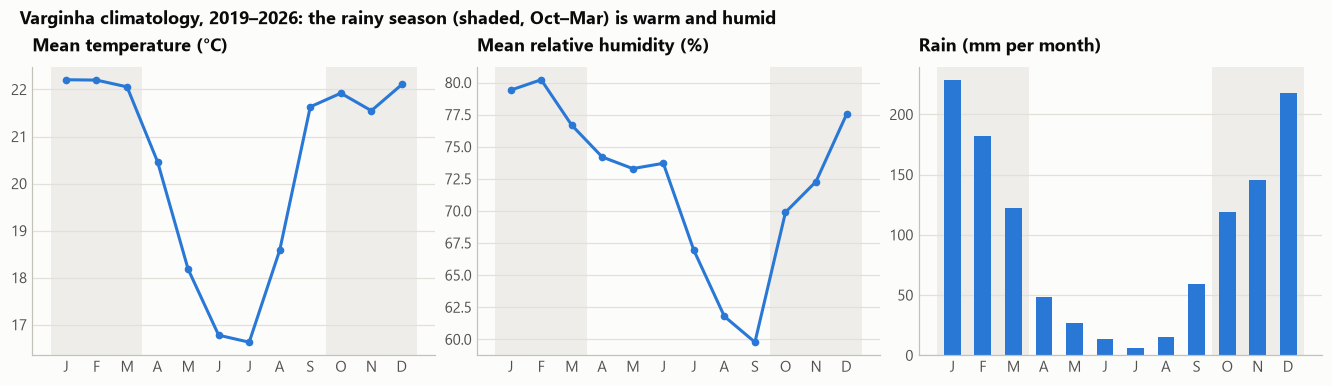

month,1,2,3,4,5,6,7,8,9,10,11,12
n,744.0,678.1,744.0,720.0,744.0,720.0,744.0,744.0,720.0,744.0,720.0,744.0
t,22.2,22.2,22.1,20.5,18.2,16.8,16.6,18.6,21.6,21.9,21.5,22.1
rh,79.4,80.2,76.7,74.2,73.3,73.7,66.9,61.8,59.8,69.9,72.3,77.5
rain,228.3,182.1,122.2,48.8,26.8,13.6,6.2,15.0,59.3,118.8,145.8,217.8


In [3]:
h = hourly.assign(year=hourly.time_local.dt.year, month=hourly.time_local.dt.month)
ym = h.groupby(["year", "month"]).agg(n=("temperature_2m", "size"), t=("temperature_2m", "mean"),
                                      rh=("relative_humidity_2m", "mean"), rain=("precipitation", "sum"))
clim = ym[ym.n >= 600].groupby("month").mean()          # complete months only
months = list("JFMAMJJASOND")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].plot(clim.index, clim.t, color=ps.BLUE, marker="o", ms=4)
axes[0].set_title("Mean temperature (°C)")
axes[1].plot(clim.index, clim.rh, color=ps.BLUE, marker="o", ms=4)
axes[1].set_title("Mean relative humidity (%)")
axes[2].bar(clim.index, clim.rain, color=ps.BLUE, width=0.55)
axes[2].set_title("Rain (mm per month)")
for ax in axes:
    ax.set_xticks(range(1, 13), months)
    ax.axvspan(0.5, 3.5, color=ps.GRID, alpha=0.5, lw=0, zorder=0)
    ax.axvspan(9.5, 12.5, color=ps.GRID, alpha=0.5, lw=0, zorder=0)
fig.suptitle("Varginha climatology, 2019–2026: the rainy season (shaded, Oct–Mar) is warm and humid",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.show()
clim.round(1).T

## 2. The biology, written as math

*H. vastatrix* urediniospores need **liquid water on the leaf** to germinate, germination is
**inhibited by light**, it works between roughly **15 and 28 °C** (best near 22 °C), and a successful
infection needs about **6 hours** of continuous wetness. Leaf wetness isn't measured, so an hour
counts as *wet* if any proxy holds: RH ≥ 90 %, dew-point depression ≤ 2 °C, or rain ≥ 0.2 mm.

The temperature effect is a beta function (Yan & Hunt 1999): 0 at the cardinal limits, 1 at the
optimum. It weights each wet hour when computing the graded `infection_score`.

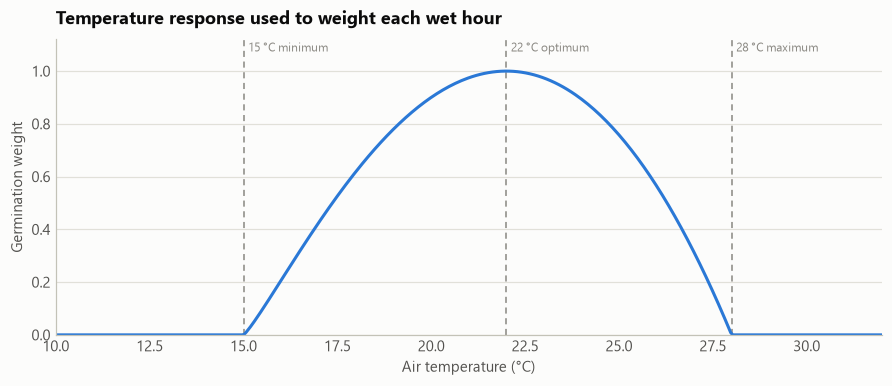

In [4]:
t = np.linspace(10, 32, 400)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(t, temperature_response(t), color=ps.BLUE)
for x, lab in [(R["t_min"], "15 °C minimum"), (R["t_opt"], "22 °C optimum"), (R["t_max"], "28 °C maximum")]:
    ps.threshold(ax, x=x, label=lab)
ax.set_ylim(0, 1.12); ax.set_xlim(10, 32)
ax.set_xlabel("Air temperature (°C)"); ax.set_ylabel("Germination weight")
ax.set_title("Temperature response used to weight each wet hour")
plt.show()

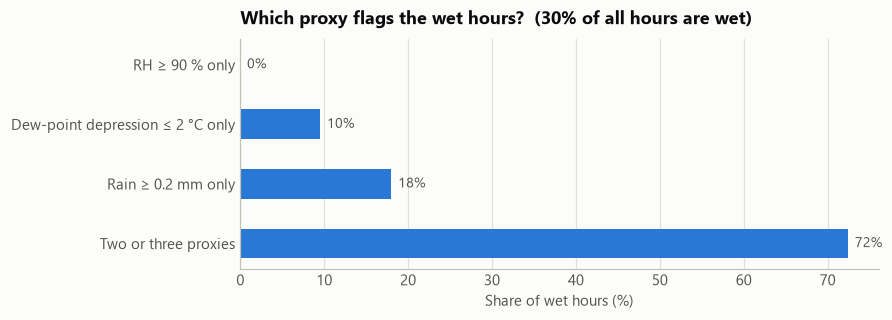

In [5]:
dpd = hourly.temperature_2m - hourly.dew_point_2m
crit = pd.DataFrame({"RH ≥ 90 %": hourly.relative_humidity_2m >= R["rh_wet"],
                     "Dew-point depression ≤ 2 °C": dpd <= R["dpd_wet"],
                     "Rain ≥ 0.2 mm": hourly.precipitation >= R["rain_wet"]})
wet = crit.any(axis=1)
only = {f"{c} only": (crit[c] & (crit.sum(axis=1) == 1)).sum() for c in crit}
only["Two or three proxies"] = (crit.sum(axis=1) >= 2).sum()
share = pd.Series(only) / wet.sum() * 100

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(share.index[::-1], share.values[::-1], color=ps.BLUE, height=0.5)
for y, v in enumerate(share.values[::-1]):
    ax.text(v + 0.8, y, f"{v:.0f}%", va="center", fontsize=9, color=ps.INK_2)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("Share of wet hours (%)")
ax.set_title(f"Which proxy flags the wet hours?  ({wet.mean():.0%} of all hours are wet)")
plt.show()

Most wet hours are flagged by more than one proxy, and **RH ≥ 90 % never fires on its own**: at
20 °C a 2 °C dew-point depression already means RH ≈ 88 %, so every RH ≥ 90 % hour also passes the
dew-point test. The dew-point rule is what really sets the threshold.

A run only *qualifies* when it also includes ≥ 4 hours of darkness, so short evening spells don't count.

## 3. Three example nights

Each "infection night" runs **noon to noon** (local time) so an overnight wet spell is never cut at
midnight. Shaded hours are *favourable*: wet **and** within 15–28 °C. A night is an infection event
when it contains an uninterrupted favourable run of ≥ 6 h with ≥ 4 h of darkness (a *qualifying* run).

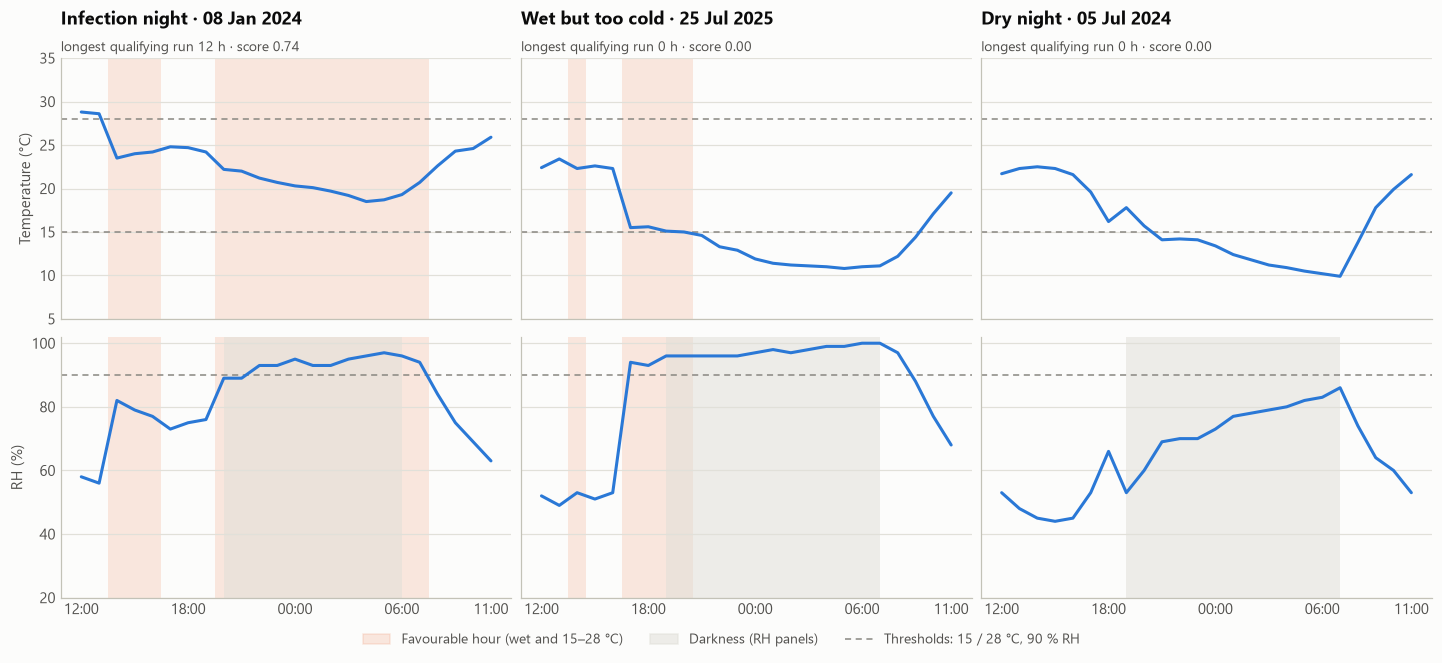

,wet_hours,fav_hours,max_run_hours,max_run_t_mean,infection_event,infection_score
night,,,,,,
2024-01-08,15,15,12.0,20.22,1,0.74
2025-07-25,18,5,0.0,NaN,0,0.00
2024-07-05,0,0,0.0,NaN,0,0.00


In [6]:
nights = label_nights(hourly)
recent = nights[nights.index >= "2024-01-01"]

ev = recent[(recent.infection_event == 1) & recent.index.month.isin([1, 2])]
event_night = (ev.max_run_hours - 12).abs().idxmin()                    # a typical ~12 h event
cold = recent[(recent.wet_hours >= 14) & (recent.infection_event == 0) & (recent.t_mean < 15.5)]
cold_night = cold.index[0]
dry = recent[(recent.wet_hours == 0) & recent.index.month.isin([7, 8])]
dry_night = dry.index[0]

def night_window(night):
    start = pd.Timestamp(night).tz_localize(config.LOCAL_TZ) + pd.Timedelta(hours=12)
    w = hourly[(hourly.time_local >= start) & (hourly.time_local < start + pd.Timedelta(hours=24))]
    return w.reset_index(drop=True)

cases = [(event_night, "Infection night"), (cold_night, "Wet but too cold"), (dry_night, "Dry night")]
fig, axes = plt.subplots(2, 3, figsize=(13, 5.6), sharex=True, sharey="row")
x = np.arange(24)
for col, (night, label) in enumerate(cases):
    w = night_window(night); f = hourly_flags(w); row = nights.loc[night]
    for r, (var, ylab) in enumerate([("temperature_2m", "Temperature (°C)"), ("relative_humidity_2m", "RH (%)")]):
        ax = axes[r, col]
        ps.shade_runs(ax, x, f.fav)
        dark = f.dark.to_numpy()
        ax.fill_between(x, 0, 1, where=dark, step="mid", transform=ax.get_xaxis_transform(),
                        color=ps.GRID, alpha=0.55, lw=0, zorder=0) if r == 1 else None
        ax.plot(x, w[var], color=ps.BLUE)
        if r == 0:
            ps.threshold(ax, y=15); ps.threshold(ax, y=28)
            ax.set_title(f"{label} · {pd.Timestamp(night):%d %b %Y}")
            ps.subtitle(ax, f"longest qualifying run {int(row.max_run_hours)} h · score {row.infection_score:.2f}")
        else:
            ps.threshold(ax, y=90)
            ax.set_ylim(20, 102)
        if col == 0:
            ax.set_ylabel(ylab)
axes[0, 0].set_ylim(5, 35)
for ax in axes[1]:
    ax.set_xticks([0, 6, 12, 18, 23], ["12:00", "18:00", "00:00", "06:00", "11:00"])
fig.legend(handles=[Patch(color=ps.WASH, label="Favourable hour (wet and 15–28 °C)"),
                    Patch(color=ps.GRID, alpha=0.55, label="Darkness (RH panels)"),
                    Line2D([], [], color=ps.MUTED, ls=(0, (4, 3)), lw=1, label="Thresholds: 15 / 28 °C, 90 % RH")],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
plt.show()
nights.loc[[event_night, cold_night, dry_night],
           ["wet_hours", "fav_hours", "max_run_hours", "max_run_t_mean", "infection_event", "infection_score"]].round(2)

The middle night is the interesting one: it is wet for many hours, but the temperature sits below
the 15 °C germination minimum, so the rule correctly says *no infection*.

## 4. Why the "24–48 consecutive hours" rule was dropped

The original brief asked for 24–48 *consecutive* hours of 15–25 °C with RH > 85 %. The chart counts,
per year, how many uninterrupted spells reach at least *X* hours under that definition and under the
literature-based one used here.

Pitch rule: 15–25 °C and RH > 85 %        spells/yr >= 6 h:  146.6   >= 24 h:  1.53   >= 48 h: 0.00
This project: wet proxy and 15–28 °C      spells/yr >= 6 h:  132.8   >= 24 h:  4.98   >= 48 h: 0.38


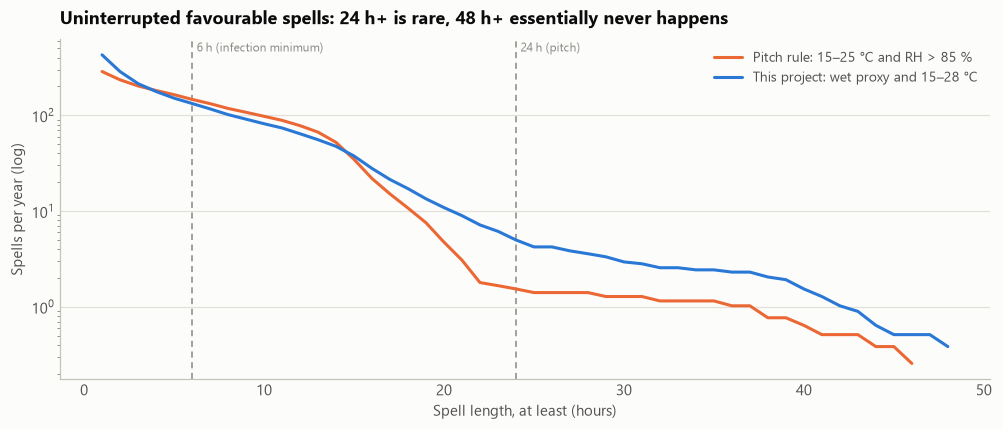

In [7]:
def run_lengths(mask):
    m = np.r_[0, np.asarray(mask, int), 0]
    edges = np.flatnonzero(np.diff(m))
    return edges[1::2] - edges[::2]

years = (hourly.time_local.max() - hourly.time_local.min()).days / 365.25
defs = {
    "Pitch rule: 15–25 °C and RH > 85 %": hourly.temperature_2m.between(15, 25) & (hourly.relative_humidity_2m > 85),
    "This project: wet proxy and 15–28 °C": leaf_wetness(hourly) & hourly.temperature_2m.between(15, 28),
}
k = np.arange(1, 49)
fig, ax = plt.subplots(figsize=(9, 3.8))
for (name, mask), color in zip(defs.items(), [ps.SERIES[1], ps.BLUE]):
    lens = run_lengths(mask)
    per_year = np.array([(lens >= kk).sum() for kk in k]) / years
    ax.plot(k[per_year > 0], per_year[per_year > 0], color=color, label=name)
    print(f"{name:40s}  spells/yr >= 6 h: {per_year[5]:6.1f}   >= 24 h: {per_year[23]:5.2f}   >= 48 h: {per_year[47]:4.2f}")
ax.set_yscale("log")
ps.threshold(ax, x=6, label="6 h (infection minimum)")
ps.threshold(ax, x=24, label="24 h (pitch)")
ax.set_xlabel("Spell length, at least (hours)"); ax.set_ylabel("Spells per year (log)")
ax.set_title("Uninterrupted favourable spells: 24 h+ is rare, 48 h+ essentially never happens")
ax.legend(loc="upper right")
plt.show()

Afternoon heating breaks the humid spell almost every day, so a 24–48 h requirement labels ~99 % of
days "safe". Nightly 6 h+ spells, by contrast, are common in the rainy season — which matches when
rust infections actually happen in Brazil.

## 5. What the labels look like

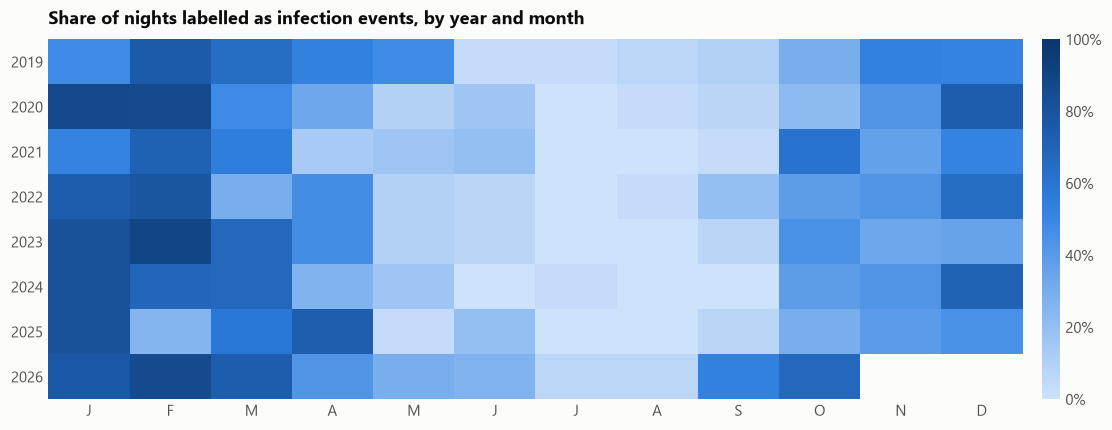

m,1,2,3,4,5,6,7,8,9,10,11,12
y,,,,,,,,,,,,
2019,48.0,75.0,65.0,53.0,48.0,3.0,3.0,6.0,10.0,29.0,53.0,52.0
2020,87.0,86.0,48.0,33.0,10.0,17.0,0.0,3.0,7.0,23.0,43.0,74.0
2021,52.0,71.0,55.0,13.0,16.0,20.0,0.0,0.0,3.0,61.0,37.0,52.0
2022,74.0,79.0,29.0,47.0,10.0,7.0,0.0,3.0,20.0,39.0,43.0,65.0
2023,81.0,89.0,68.0,47.0,10.0,7.0,0.0,0.0,7.0,45.0,33.0,35.0
2024,81.0,69.0,68.0,27.0,16.0,0.0,3.0,0.0,0.0,39.0,43.0,71.0
2025,81.0,25.0,58.0,73.0,3.0,20.0,0.0,0.0,7.0,29.0,40.0,45.0
2026,77.0,86.0,74.0,43.0,29.0,27.0,6.0,6.0,53.0,68.0,NaN,NaN


In [8]:
piv = nights.assign(y=nights.index.year, m=nights.index.month).pivot_table(index="y", columns="m", values="infection_event")
fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(piv.values, cmap=ps.BLUE_CMAP, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(12), months); ax.set_yticks(range(len(piv)), piv.index)
ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, format=lambda v, _: f"{v:.0%}")
cb.outline.set_visible(False); cb.ax.tick_params(colors=ps.INK_2)
ax.set_title("Share of nights labelled as infection events, by year and month")
plt.show()
(piv * 100).round(0)

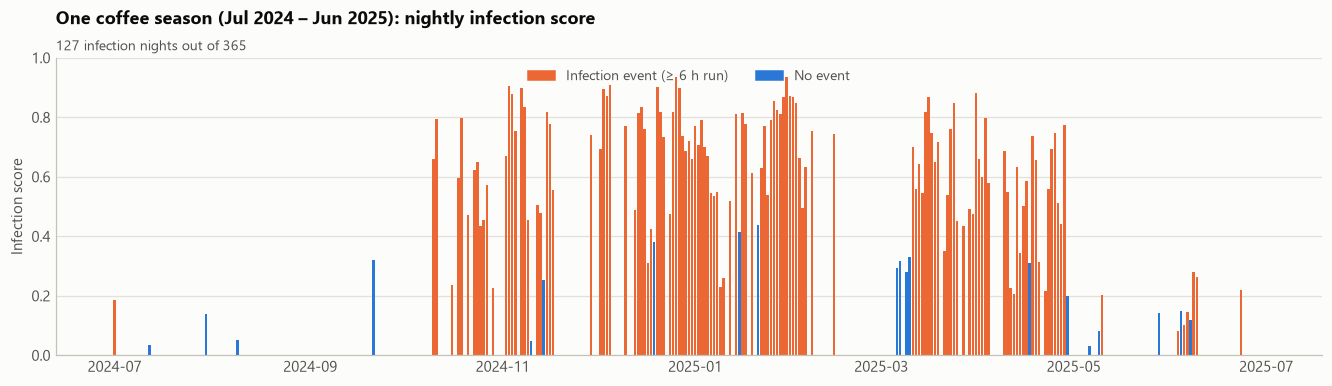

In [9]:
season = nights.loc["2024-07-01":"2025-06-30"]
colors = np.where(season.infection_event == 1, ps.SERIES[1], ps.BLUE)
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.bar(season.index, season.infection_score, width=0.8, color=colors)
ax.set_ylim(0, 1); ax.set_ylabel("Infection score")
ax.set_title("One coffee season (Jul 2024 – Jun 2025): nightly infection score")
ps.subtitle(ax, f"{season.infection_event.sum()} infection nights out of {len(season)}")
ax.legend(handles=[Patch(color=ps.SERIES[1], label="Infection event (≥ 6 h run)"),
                   Patch(color=ps.BLUE, label="No event")], loc="upper center", ncol=2)
plt.show()

## 6. How sensitive are the labels to the thresholds?

Every threshold is a judgement call, so it's worth seeing how much the positive rate moves.

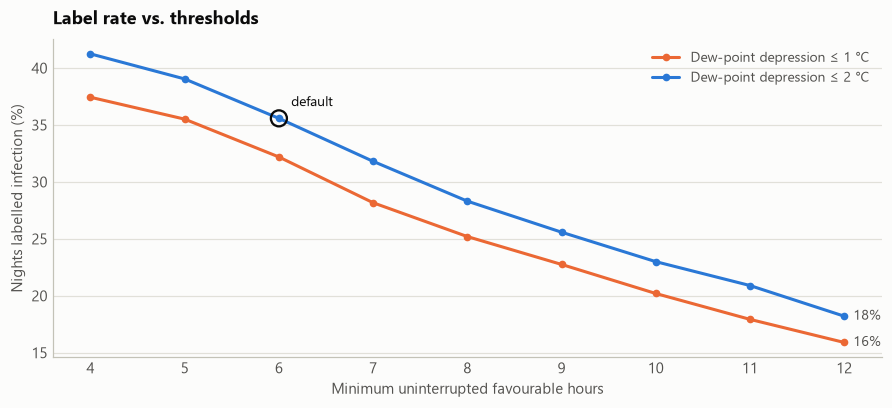

In [10]:
rows = []
for dpd_ in (1.0, 2.0):
    for mh in range(4, 13):
        lab = label_nights(hourly, dict(R, dpd_wet=dpd_, min_wet_hours=mh))
        rows.append({"dpd": dpd_, "min_hours": mh, "rate": lab.infection_event.mean()})
sens = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 3.6))
for (dpd_, g), color in zip(sens.groupby("dpd"), [ps.SERIES[1], ps.BLUE]):
    ax.plot(g.min_hours, g.rate * 100, color=color, marker="o", ms=4, label=f"Dew-point depression ≤ {dpd_:g} °C")
    ax.annotate(f"{g.rate.iloc[-1]:.0%}", (g.min_hours.iloc[-1], g.rate.iloc[-1] * 100),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=ps.INK_2)
default = sens[(sens.dpd == R["dpd_wet"]) & (sens.min_hours == R["min_wet_hours"])].iloc[0]
ax.scatter([default.min_hours], [default.rate * 100], s=110, facecolor="none", edgecolor=ps.INK, lw=1.5, zorder=3)
ax.annotate("default", (default.min_hours, default.rate * 100), xytext=(8, 8), textcoords="offset points", fontsize=9)
ax.set_xlabel("Minimum uninterrupted favourable hours"); ax.set_ylabel("Nights labelled infection (%)")
ax.set_title("Label rate vs. thresholds")
ax.legend(loc="upper right")
plt.show()

## Takeaways

- The labels follow the expected biology: frequent in the warm rainy season, rare in the dry winter,
  and suppressed on wet-but-cold nights.
- In Jan–Feb most nights qualify, so **weather is rarely the limiting factor at peak season**; the
  forecast is most informative at the season's shoulders (Oct–Nov, Mar–May).
- The defaults follow the literature; the positive rate is most sensitive to the dew-point proxy and
  the minimum-duration threshold, both configurable in `src/config.py`.

Next: `02_features_and_gpu_xgboost.ipynb` turns these labels into a 7-night forecasting model.